# 167. Two Sum II - Input Array Is Sorted
**Difficulty:** 🟡 Medium · **Topic:** Two Pointers · **Pattern:** [Opposite Ends](README.md) · **LeetCode:** https://leetcode.com/problems/two-sum-ii-input-array-is-sorted/

## 💡 Concepts

**Core concept(s):** **Two pointers from opposite ends** on a **sorted** array.

**Why it applies here:**
- The array is already sorted, so the sum of the two ends tells you which end is useless.
- Sum too small → the left value is too small to pair with *anything* still in range, so drop it (`lo += 1`).
- Sum too big → the right value is too big to pair with anything still in range, so drop it (`hi -= 1`).
- The problem asks for `O(1)` extra space, which rules out the hash map trick from the original Two Sum.

**Key intuition:**
- Every step throws away one value that provably cannot be in the answer.
- After at most `n - 1` steps the pointers meet, so the scan is linear.

---

### 📚 What is a Sorted Array?
- A **sorted array** keeps its values in non-decreasing order: `nums[0] <= nums[1] <= ...`.
- Moving right can only make a value bigger (or equal); moving left can only make it smaller (or equal).
- That one-way property is what lets a single comparison decide which pointer to move.
- **In Python:** a plain `list`; sorting one yourself costs `O(n log n)` (`sorted(nums)`), here it comes pre-sorted.

### 📚 What is the Two-Pointer Technique (opposite ends)?
- Two integer indices, `lo` at the start and `hi` at the end, that walk toward each other.
- Each step looks at the pair `(nums[lo], nums[hi])` and moves exactly one pointer inward.
- They stop when they meet, so the loop runs at most `n - 1` times.
- **Complexity:** `O(n)` time, `O(1)` extra space (just two integers).
- **In Python:** two `int` variables and a `while lo < hi:` loop.

### 📚 What is a Hash Map? (used by Approach 2)
- A hash map (Python `dict`) stores key → value pairs.
- It hashes each key to a slot in an array, so it jumps straight to the value instead of scanning.
- Insert and lookup are **O(1) on average**.
- **In Python:** `dict`, e.g. `seen[value] = index`.
- Why it matters here: it solves the problem in `O(n)` time but spends `O(n)` memory, which the problem forbids.

---

**Prerequisite knowledge:**
- The original [Two Sum](https://leetcode.com/problems/two-sum/) (hash map of complements).
- Indexes here are **1-based** in the answer: return `[i + 1, j + 1]`.

## 📝 Problem

Given a **1-indexed** array `numbers` sorted in non-decreasing order, find two numbers that add up to `target`. Return their indices `[index1, index2]` with `1 <= index1 < index2`, both shifted by one. Exactly one solution exists, and you may not use the same element twice. Use only **constant extra space**.

**Example 1**
```
numbers = [2, 7, 11, 15], target = 9   ->  [1, 2]     (2 + 7 = 9)
```

**Example 2** (used for the step-through)
```
numbers = [1, 3, 4, 5, 7, 10, 11], target = 9   ->  [3, 4]     (4 + 5 = 9)
```

**Constraints:** `2 <= numbers.length <= 3 * 10^4`, `-1000 <= numbers[i] <= 1000`, exactly one solution.

> Three approaches: brute force over every pair (`O(n²)`), a hash map of seen values (`O(n)` time but `O(n)` space), and opposite-end two pointers (`O(n)` time, `O(1)` space).

In [1]:
from typing import List

### Approach 1 — Brute Force: try every pair

**Idea:**
1. For each index `i`, try every later index `j`.
2. Return the first pair whose values add up to `target`.

**Time complexity:** `O(n²)` — up to `n(n-1)/2` pairs are checked.

**Space complexity:** `O(1)` — two loop indices.

In [2]:
def two_sum_ii_brute(numbers: List[int], target: int) -> List[int]:
    n = len(numbers)
    for i in range(n):                         # first number of the pair
        for j in range(i + 1, n):              # every later number
            if numbers[i] + numbers[j] == target:
                return [i + 1, j + 1]          # answer is 1-indexed
    return []                                  # unreachable: exactly one solution exists

### Approach 2 — Hash Map of seen values (ignores the sorted order)

**Idea:** the original Two Sum trick.
1. Walk left to right; for each value `x`, the partner it needs is `target - x`.
2. If that partner was already seen, return both indices.
3. Otherwise remember `x -> index` and keep going.

**Time complexity:** `O(n)` — one pass with `O(1)` average lookups.

**Space complexity:** `O(n)` — the map can hold nearly every value. This breaks the problem's constant-space rule: it works, but it is the wrong tool for sorted input.

In [3]:
def two_sum_ii_hashmap(numbers: List[int], target: int) -> List[int]:
    seen = {}                                  # value -> index where we saw it
    for j, x in enumerate(numbers):
        need = target - x                      # the partner that completes the pair
        if need in seen:
            return [seen[need] + 1, j + 1]     # earlier index first, both 1-indexed
        seen[x] = j
    return []

### Approach 3 — Two Pointers from opposite ends (optimal · pattern template)

**Idea:** the [Opposite Ends](README.md) template, with the sum deciding which pointer moves.
1. `lo = 0`, `hi = n - 1`.
2. Compute `s = numbers[lo] + numbers[hi]`.
3. `s == target` → done. `s < target` → `numbers[lo]` is too small even with the biggest value left, so `lo += 1`. `s > target` → `numbers[hi]` is too big even with the smallest value left, so `hi -= 1`.
4. Repeat while `lo < hi`.

**Time complexity:** `O(n)` — each step moves one pointer inward, at most `n - 1` steps.

**Space complexity:** `O(1)` — two indices.

In [4]:
def two_sum_ii_two_pointers(numbers: List[int], target: int) -> List[int]:
    lo, hi = 0, len(numbers) - 1               # one pointer at each end
    while lo < hi:
        s = numbers[lo] + numbers[hi]
        if s == target:
            return [lo + 1, hi + 1]            # 1-indexed answer
        if s < target:
            lo += 1                            # numbers[lo] is too small for every partner left: drop it
        else:
            hi -= 1                            # numbers[hi] is too big for every partner left: drop it
    return []

In [5]:
# Correctness check
import random

tests = [
    ([2, 7, 11, 15], 9, [1, 2]),               # LeetCode example 1
    ([2, 3, 4], 6, [1, 3]),                    # LeetCode example 2
    ([-1, 0], -1, [1, 2]),                     # LeetCode example 3: negatives, n = 2
    ([1, 3, 4, 5, 7, 10, 11], 9, [3, 4]),      # the step-through example
    ([0, 0, 3, 4], 0, [1, 2]),                 # duplicate values form the pair
    ([1, 2, 3, 4, 4, 9, 56, 90], 8, [4, 5]),   # equal values in the middle
]
for nums, target, exp in tests:
    a = two_sum_ii_brute(nums, target)
    b = two_sum_ii_hashmap(nums, target)
    c = two_sum_ii_two_pointers(nums, target)
    print(f"{str(nums):28} target={target:>3} -> {c}")
    assert a == b == c == exp, f"mismatch on {nums}, {target}: brute={a} hashmap={b} two_pointers={c}"

# Randomised cross-check: plant exactly one valid pair in random sorted arrays
rng = random.Random(167)
for _ in range(300):
    nums = sorted(rng.sample(range(-1000, 1000), rng.randint(2, 30)))   # distinct values
    i, j = sorted(rng.sample(range(len(nums)), 2))
    target = nums[i] + nums[j]
    pairs = [(a, b) for a in range(len(nums)) for b in range(a + 1, len(nums)) if nums[a] + nums[b] == target]
    if len(pairs) != 1:
        continue                                # the problem guarantees a unique answer
    exp = [pairs[0][0] + 1, pairs[0][1] + 1]
    assert two_sum_ii_brute(nums, target) == two_sum_ii_hashmap(nums, target) == two_sum_ii_two_pointers(nums, target) == exp
print("random sorted arrays with a unique pair: all three approaches agree")

print("\nAll tests passed")

[2, 7, 11, 15]               target=  9 -> [1, 2]
[2, 3, 4]                    target=  6 -> [1, 3]
[-1, 0]                      target= -1 -> [1, 2]
[1, 3, 4, 5, 7, 10, 11]      target=  9 -> [3, 4]
[0, 0, 3, 4]                 target=  0 -> [1, 2]
[1, 2, 3, 4, 4, 9, 56, 90]   target=  8 -> [4, 5]
random sorted arrays with a unique pair: all three approaches agree

All tests passed


## ⏱️ Empirically Checking the Complexities

Big-O can't be read off a function directly, but it can be **measured**. We time each approach on inputs of growing `n` and read the **doubling ratio** — how much runtime grows when `n` doubles.

| Theoretical | Ratio when `n` → `2n` |
|-------------|-----------------------|
| `O(n)`        | ≈ **2×** |
| `O(n²)`       | ≈ **4×** |

**Worst-case input:** `[1, 2, ..., n-2, 3n, 3n+1]` with `target = 6n + 1`. The only valid pair is the last two values, so the brute force scans every pair, the hash map reaches the last element, and the two pointers walk `lo` all the way to `n - 2`. No approach exits early.


brute        O(n^2)
        n |  time (ms) | ratio vs prev
  ------- | ---------- | -------------
      500 |       2.70 |           n/a
     1000 |      11.14 |         4.13x
     2000 |      46.55 |         4.18x


     4000 |     181.67 |         3.90x

hashmap      O(n)  
        n |  time (ms) | ratio vs prev
  ------- | ---------- | -------------
      500 |       0.03 |           n/a
     1000 |       0.05 |         1.59x
     2000 |       0.09 |         1.61x
     4000 |       0.20 |         2.25x

two pointers O(n)  
        n |  time (ms) | ratio vs prev
  ------- | ---------- | -------------
      500 |       0.04 |           n/a
     1000 |       0.04 |         0.95x
     2000 |       0.09 |         2.54x
     4000 |       0.23 |         2.46x

Ratios per doubling: ~1x=>constant/log, ~2x=>linear or n log n, ~4x=>quadratic, ~8x=>cubic.


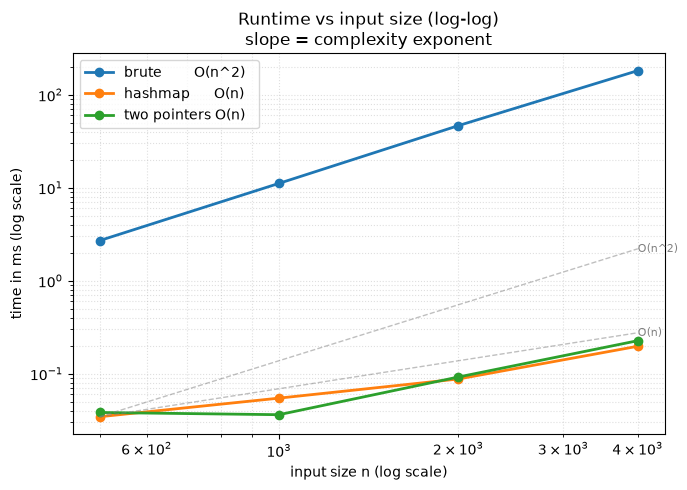

{'brute        O(n^2)': [2.699416014365852,
  11.136665940284729,
  46.54875001870096,
  181.66595802176744],
 'hashmap      O(n)  ': [0.03445800393819809,
  0.054625095799565315,
  0.08775002788752317,
  0.1973749604076147],
 'two pointers O(n)  ': [0.03829097840934992,
  0.036250101402401924,
  0.09216601029038429,
  0.22654107306152582]}

In [6]:
import os, sys
_root = os.getcwd()
for _ in range(5):
    if os.path.exists(os.path.join(_root, "bench_utils.py")):
        break
    _root = os.path.dirname(_root)
if _root not in sys.path:
    sys.path.insert(0, _root)
from bench_utils import benchmark   # shared: prints ratio table + optional log-log plot

def make_worst_case(n):
    numbers = list(range(1, n - 1)) + [3 * n, 3 * n + 1]   # unique answer = the last two
    return (numbers, 6 * n + 1)

solutions = {
    "brute        O(n^2)": two_sum_ii_brute,
    "hashmap      O(n)  ": two_sum_ii_hashmap,
    "two pointers O(n)  ": two_sum_ii_two_pointers,
}
sizes = [500, 1000, 2000, 4000]

benchmark(solutions, make_worst_case, sizes, plot=True)

## 🧩 Patterns Learned

- **Pattern:** [Opposite Ends](README.md) — the template in its purest form: the pair sum versus `target` decides which end to drop.
- **Sorted input + pair condition → opposite-end two pointers:** each comparison rules out one whole row (or column) of the pair grid, so `O(n²)` pairs collapse to `O(n)` steps.
- **The hash map is the wrong tool here:** it ignores the sorted order and pays `O(n)` memory the problem forbids.
- **Signal:** "sorted array", "pair that sums to target", "constant extra space".
- **Related problems:** 3Sum (fix one number, then this exact loop), 3Sum Closest, 4Sum, Two Sum (unsorted → hash map).
- **Common pitfalls:**
  1. Returning 0-based indices — this problem is 1-indexed.
  2. Moving both pointers after a miss — only the side that was proven useless may move.
  3. Using `lo <= hi` — that would pair an element with itself.